##                                             **AUTOMOBILE PRICE PREDICTION**


## Project Overview



| **Goal** | Predict the **price** of a car from its specifications (engine size, horsepower, weight, mileage, brand, etc.) |

| **Dataset** | Automobile (Imports-85) dataset: 201 cars, 25 input features + 1 target (`price`) |

| **Problem type** | Supervised learning, **regression** |

| **Models compared** | Linear Regression, Decision Tree, Random Forest, Gradient Boosting |

| **Metrics** | MAE, RMSE (lower is better) and R² (closer to 1 is better) |

In [1]:
# Imports
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# Set plotting defaults so Seaborn uses a valid Matplotlib color cycle.
sns.set_theme()

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
columns = [
    "symboling", "normalized-losses", "make", "fuel-type", "aspiration",
    "num-of-doors", "body-style", "drive-wheels", "engine-location",
    "wheel-base", "length", "width", "height", "curb-weight",
    "engine-type", "num-of-cylinders", "engine-size", "fuel-system",
    "bore", "stroke", "compression-ratio", "horsepower", "peak-rpm",
    "city-mpg", "highway-mpg", "price"
]

#In the original dataset, missing values are represented by the symbol ?.
#While loading the dataset, we used the na_values="?" 
#parameter in Pandas to convert these symbols into standard missing values (NaN).

df = pd.read_csv("auto_imports.csv", header=None, names=columns, na_values=["?"])



## 1. Basic checks

Before any analysis we need to understand what the data looks like: its size, column types, missing values and the target variable.


In [3]:
df.head()

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450


In [4]:
df.tail()

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
196,-1,95.0,volvo,gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114.0,5400.0,23,28,16845
197,-1,95.0,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160.0,5300.0,19,25,19045
198,-1,95.0,volvo,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134.0,5500.0,18,23,21485
199,-1,95.0,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.40,23.0,106.0,4800.0,26,27,22470
200,-1,95.0,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114.0,5400.0,19,25,22625


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          201 non-null    int64  
 1   normalized-losses  164 non-null    float64
 2   make               201 non-null    object 
 3   fuel-type          201 non-null    object 
 4   aspiration         201 non-null    object 
 5   num-of-doors       199 non-null    object 
 6   body-style         201 non-null    object 
 7   drive-wheels       201 non-null    object 
 8   engine-location    201 non-null    object 
 9   wheel-base         201 non-null    float64
 10  length             201 non-null    float64
 11  width              201 non-null    float64
 12  height             201 non-null    float64
 13  curb-weight        201 non-null    int64  
 14  engine-type        201 non-null    object 
 15  num-of-cylinders   201 non-null    object 
 16  engine-size        201 non

 Statistical summary
- `describe()` gives mean, min, max and quartiles for **numeric** columns.
- `describe(include='O')` gives count, unique values and the most frequent value for **categorical** columns.

In [6]:
df.describe()

,symboling,normalized-losses,wheel-base,length,width,height,curb-weight,engine-size,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
count,201.000000,164.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,197.000000,197.000000,201.000000,199.000000,199.000000,201.000000,201.000000,201.000000
mean,0.840796,122.000000,98.797015,174.200995,65.889055,53.766667,2555.666667,126.875622,3.330711,3.256904,10.164279,103.396985,5117.587940,25.179104,30.686567,13207.129353
std,1.254802,35.442168,6.066366,12.322175,2.101471,2.447822,517.296727,41.546834,0.270793,0.319256,4.004965,37.553843,480.521824,6.423220,6.815150,7947.066342
min,-2.000000,65.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,0.000000,94.000000,94.500000,166.800000,64.100000,52.000000,2169.000000,98.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7775.000000
50%,1.000000,115.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,2.000000,150.000000,102.400000,183.500000,66.600000,55.500000,2926.000000,141.000000,3.590000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16500.000000
max,3.000000,256.000000,120.900000,208.100000,72.000000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,262.000000,6600.000000,49.000000,54.000000,45400.000000


In [7]:
df.describe(include='O')

,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,engine-type,num-of-cylinders,fuel-system
count,201,201,201,199,201,201,201,201,201,201
unique,22,2,2,2,5,3,2,6,7,8
top,toyota,gas,std,four,sedan,fwd,front,ohc,four,mpfi
freq,32,181,165,113,94,118,198,145,157,92


In [8]:
df.isnull().sum()

symboling             0
normalized-losses    37
make                  0
fuel-type             0
aspiration            0
num-of-doors          2
body-style            0
drive-wheels          0
engine-location       0
wheel-base            0
length                0
width                 0
height                0
curb-weight           0
engine-type           0
num-of-cylinders      0
engine-size           0
fuel-system           0
bore                  4
stroke                4
compression-ratio     0
horsepower            2
peak-rpm              2
city-mpg              0
highway-mpg           0
price                 0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.shape

(201, 26)

In [11]:
df.columns

Index(['symboling', 'normalized-losses', 'make', 'fuel-type', 'aspiration',
       'num-of-doors', 'body-style', 'drive-wheels', 'engine-location',
       'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-type',
       'num-of-cylinders', 'engine-size', 'fuel-system', 'bore', 'stroke',
       'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg',
       'highway-mpg', 'price'],
      dtype='object')

In [12]:
#Check the target variable
print(df["price"].describe())
print("Missing prices:", df["price"].isnull().sum())

#price is the value we want to predict. 
#We check its distribution and make sure it has no missing values (rows without a price cannot be used for training).

count      201.000000
mean     13207.129353
std       7947.066342
min       5118.000000
25%       7775.000000
50%      10295.000000
75%      16500.000000
max      45400.000000
Name: price, dtype: float64
Missing prices: 0


In [13]:
# Calculate missing values and percentages
missing_report = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

missing_report = missing_report[
    missing_report["Missing_Count"] > 0
].sort_values("Missing_Count", ascending=False)

display(missing_report)

,Missing_Count,Missing_Percentage
normalized-losses,37,18.41
bore,4,1.99
stroke,4,1.99
num-of-doors,2,1.00
horsepower,2,1.00
peak-rpm,2,1.00


In [14]:
display(df.dtypes)

symboling              int64
normalized-losses    float64
make                  object
fuel-type             object
aspiration            object
num-of-doors          object
body-style            object
drive-wheels          object
engine-location       object
wheel-base           float64
length               float64
width                float64
height               float64
curb-weight            int64
engine-type           object
num-of-cylinders      object
engine-size            int64
fuel-system           object
bore                 float64
stroke               float64
compression-ratio    float64
horsepower           float64
peak-rpm             float64
city-mpg               int64
highway-mpg            int64
price                  int64
dtype: object

---
## Separate Numerical and Categorical Columns

**Why?** Numeric and categorical data are treated differently (for example, different ways of filling missing values and different charts), so we split them into two groups.

In [15]:
# seperate the numerical and categorical data 
numerical_col = df.select_dtypes(include=np.number)
categorical_col = df.select_dtypes(include="object")

**Numerical columns:**

In [16]:
numerical_col.columns.tolist()

['symboling',
 'normalized-losses',
 'wheel-base',
 'length',
 'width',
 'height',
 'curb-weight',
 'engine-size',
 'bore',
 'stroke',
 'compression-ratio',
 'horsepower',
 'peak-rpm',
 'city-mpg',
 'highway-mpg',
 'price']

**Categorical columns:**

In [17]:
categorical_col.columns.tolist()

['make',
 'fuel-type',
 'aspiration',
 'num-of-doors',
 'body-style',
 'drive-wheels',
 'engine-location',
 'engine-type',
 'num-of-cylinders',
 'fuel-system']

**Missing values in each group:**

In [18]:
# Check missing values in numerical columns
print("Missing values in numerical columns:")
print(numerical_col.isnull().sum()[numerical_col.isnull().sum() > 0])

# Check missing values in categorical columns
print("\nMissing values in categorical columns:")
print(categorical_col.isnull().sum()[categorical_col.isnull().sum() > 0])

Missing values in numerical columns:
normalized-losses    37
bore                  4
stroke                4
horsepower            2
peak-rpm              2
dtype: int64

Missing values in categorical columns:
num-of-doors    2
dtype: int64


---
## Handle Missing Values (for EDA only)

> **Important:** `df_clean` is used **only for visualisation (EDA)**. It is **not** used for model training. For modelling, missing values are filled *after* the train/test split (see Section 8) to avoid data leakage.

In [19]:
# Create a cleaned copy for exploratory data analysis (EDA) only.
# IMPORTANT: Do not use df_clean for model training.
# Model training uses X_train-derived fill values AFTER the train/test split
# (see Section 3.1), so test-set information is not used for imputation.
df_clean = df.copy()

# Fill missing numerical values for plotting/EDA only
for col in numerical_col.columns:
    if df_clean[col].isnull().any():
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Fill missing categorical values for plotting/EDA only
for col in categorical_col.columns:
    if df_clean[col].isnull().any():
        modes = df_clean[col].mode(dropna=True)
        if not modes.empty:
            df_clean[col] = df_clean[col].fillna(modes.iloc[0])


**Verify the cleaning:** the total number of missing values should now be 0.

In [20]:
print("Missing values after cleaning:")
print(df_clean.isnull().sum().sum())

print("Dataset shape:", df_clean.shape)


Missing values after cleaning:
0
Dataset shape: (201, 26)


In [21]:
df_clean.isnull().sum()

symboling            0
normalized-losses    0
make                 0
fuel-type            0
aspiration           0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 0
stroke               0
compression-ratio    0
horsepower           0
peak-rpm             0
city-mpg             0
highway-mpg          0
price                0
dtype: int64

---
##  2.Exploratory Data Analysis (EDA)

EDA means looking at the data with charts to find patterns, outliers and relationships *before* building models.


## 2.1 Distribution of numerical features (histograms)

 
Each histogram shows how the values of one feature are spread. The curve is a smooth estimate of the distribution (KDE). This helps spot skewed features.

In [22]:
# histogram for numerical columns 
numerical_col.shape

(201, 16)

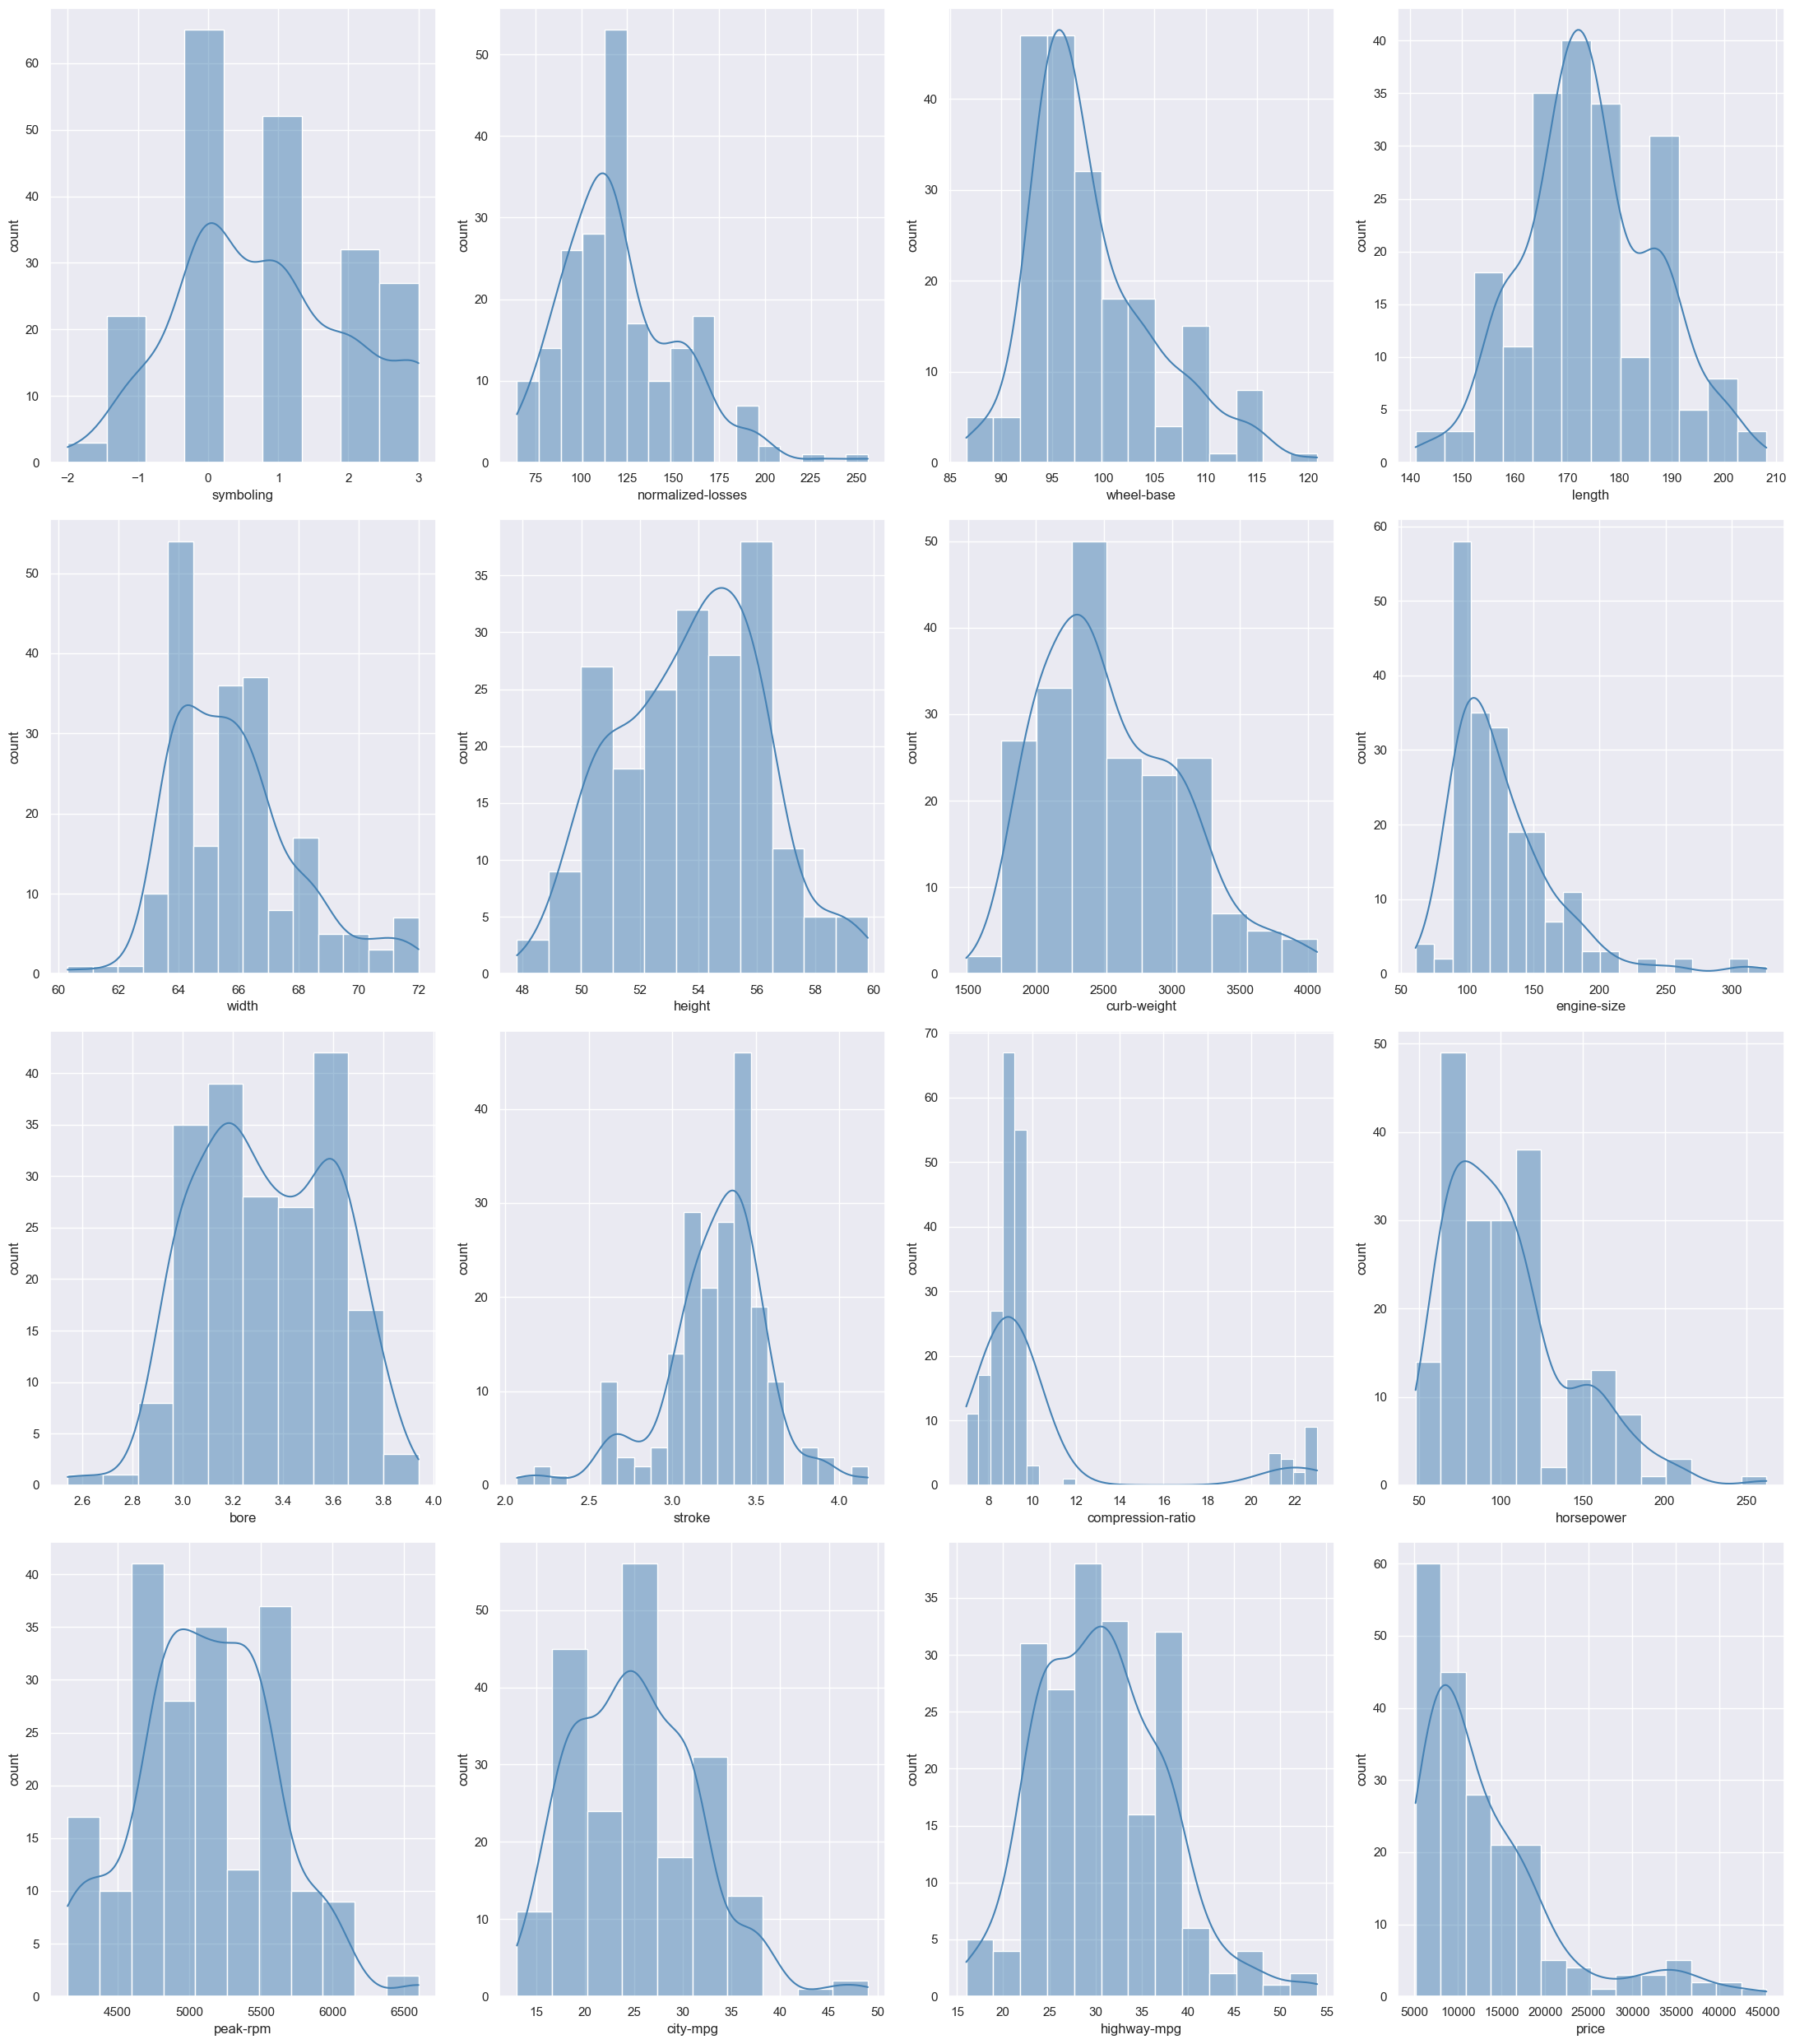

In [23]:
plt.figure(figsize=(22,25))
plotnumber=1
for column in numerical_col.columns:
    if plotnumber<=16:
        ax=plt.subplot(4,4,plotnumber)
        sns.histplot(df_clean[column], kde=True, color="steelblue")
        plt.xlabel(column)
        plt.ylabel("count")
    plotnumber+=1
plt.tight_layout()
plt.show()

### 2.2 Outlier detection (box plots)
A box plot shows the median, the middle 50% of the data and, as individual dots, **potential outliers** (unusually high or low values).

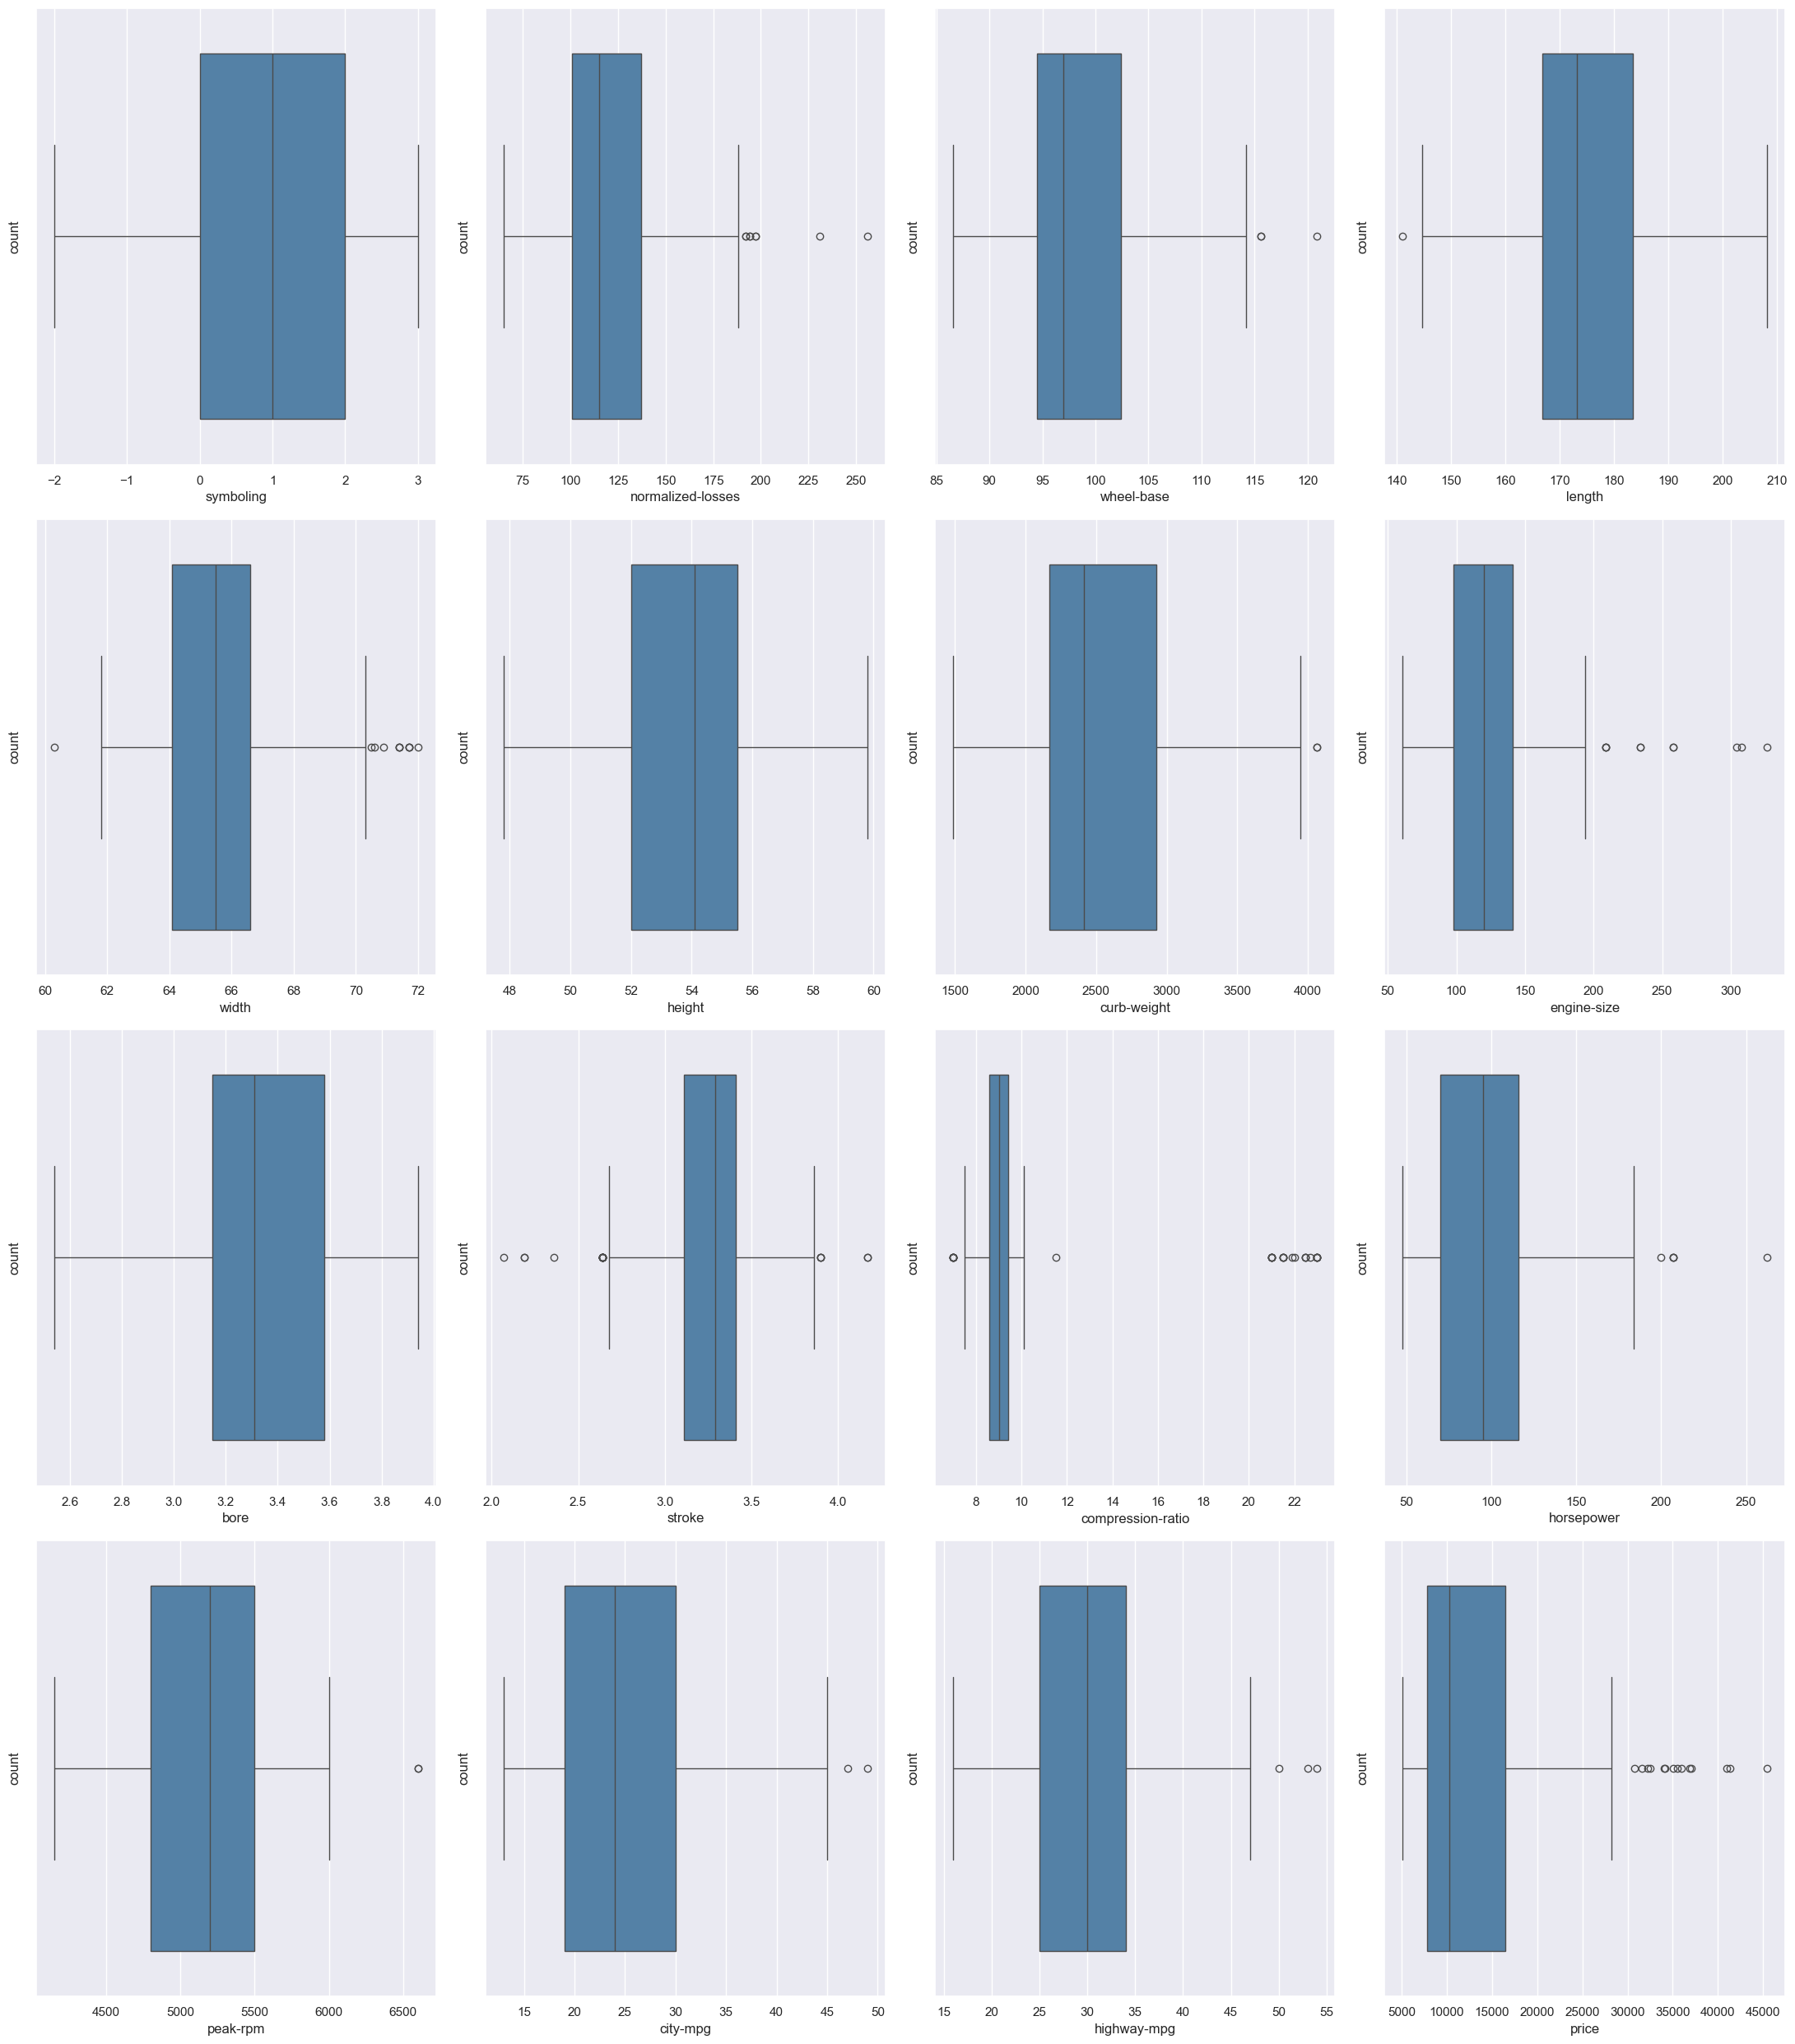

In [24]:
# boxplot : used to display the outliers
plt.figure(figsize=(22,25))
plotnumber=1
for column in numerical_col.columns:
    if plotnumber<=16:
        ax=plt.subplot(4,4,plotnumber)
        sns.boxplot(x=df_clean[column], color="steelblue")
        plt.xlabel(column)
        plt.ylabel("count")
    plotnumber+=1
plt.tight_layout()
plt.show()

### 2.3 Categorical features (count plots)
Each bar shows how many cars belong to each category. This reveals which categories are common (for example, the most frequent make or body style) and which are rare.

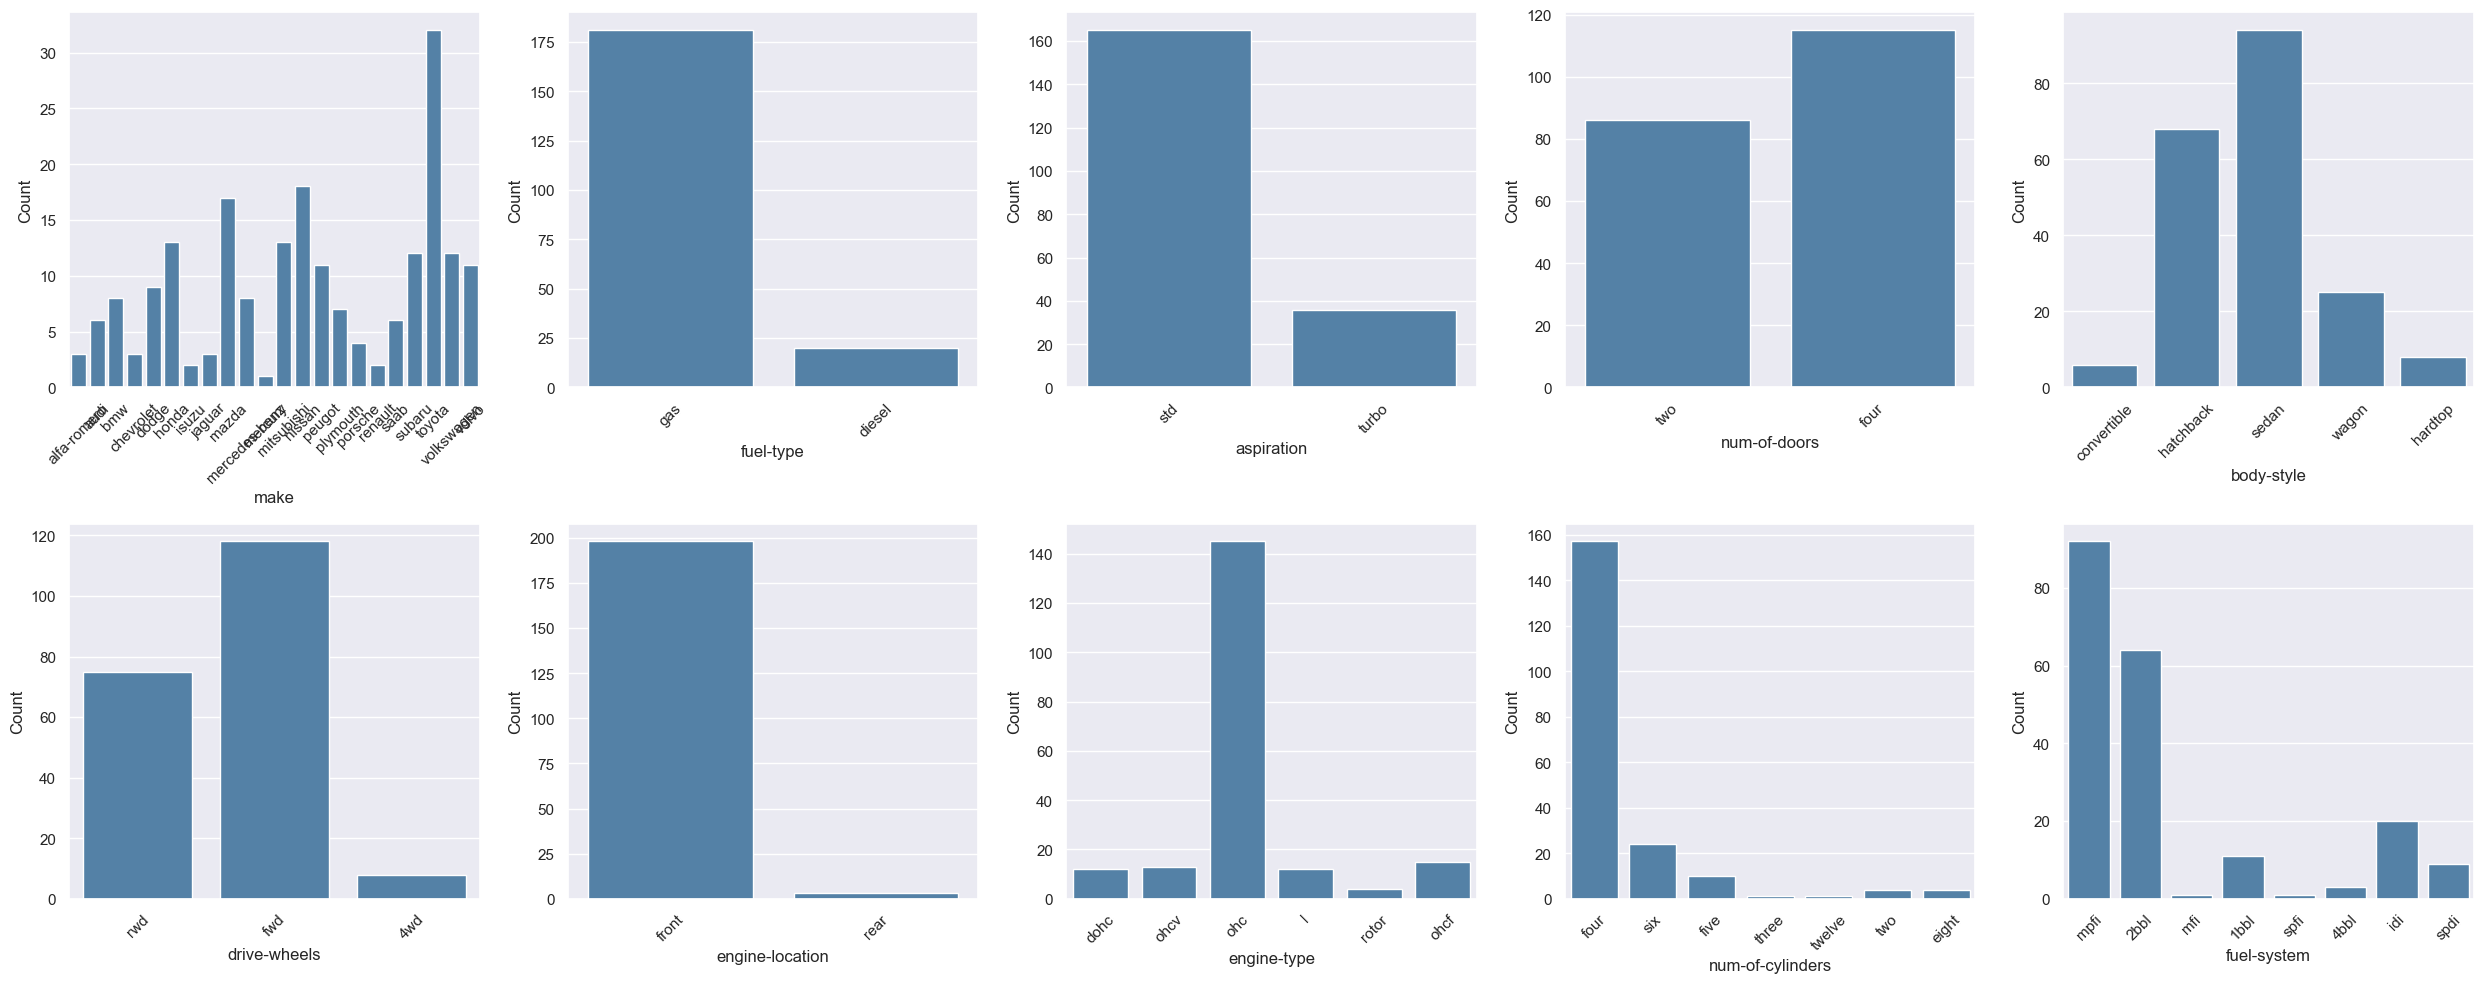

In [25]:
# Count plot: used to count the occurrence of each category

plt.figure(figsize=(25, 10))
plotnumber = 1

for column in categorical_col.columns:
    if plotnumber <= 10:
        ax = plt.subplot(2, 5, plotnumber)

        sns.countplot(data=df_clean, x=column, color="steelblue")

        plt.xlabel(column)
        plt.ylabel("Count")
        plt.xticks(rotation=45)

    plotnumber += 1

plt.tight_layout()
plt.show()

### 2.4 Relationship between features and price (scatter plots)
Scatter plots show how `price` changes as another feature changes. We look at six important features: engine size, horsepower, curb weight, highway MPG, city MPG and width.

In [26]:
# scatter plot used to understand the relatinship between the two features 
features = [
    "engine-size",
    "horsepower",
    "curb-weight",
    "highway-mpg",
    "city-mpg",
    "width"
]

**Engine size vs Price**

<Axes: xlabel='engine-size', ylabel='price'>

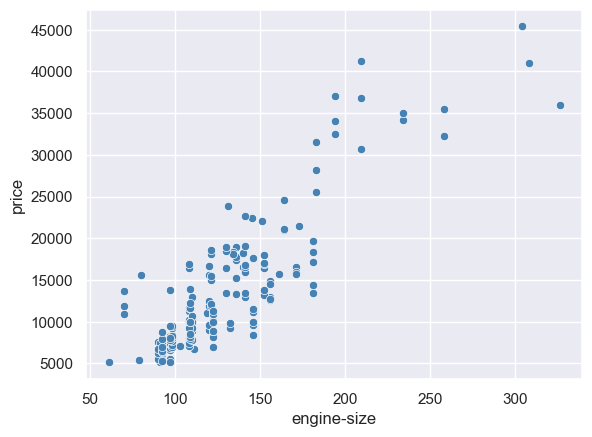

In [27]:
sns.scatterplot(data=df_clean,x="engine-size",y='price', color="steelblue")

**Horsepower vs Price**

<Axes: xlabel='horsepower', ylabel='price'>

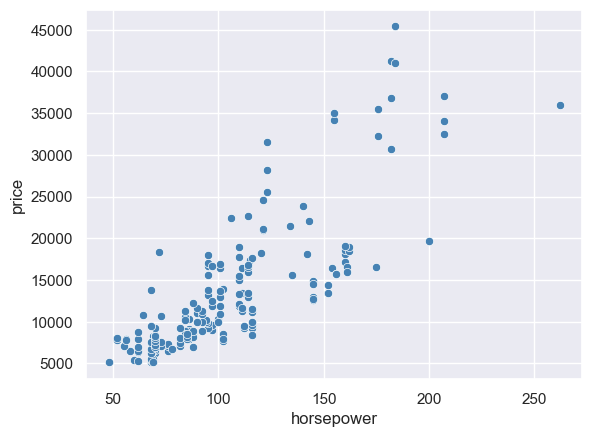

In [28]:
sns.scatterplot(data=df_clean,x="horsepower",y='price', color="steelblue")

**Curb weight vs Price**

<Axes: xlabel='curb-weight', ylabel='price'>

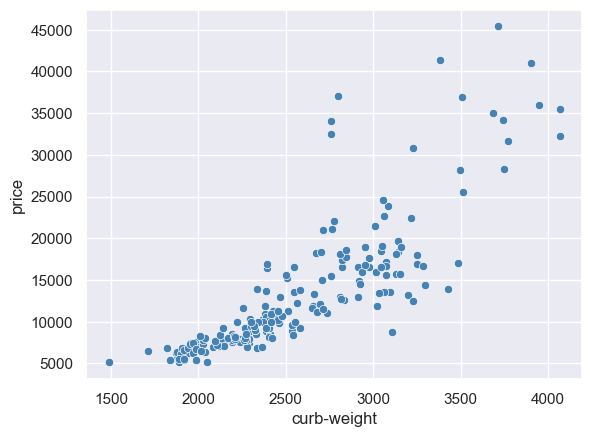

In [29]:
sns.scatterplot(data=df_clean,x="curb-weight",y='price', color="steelblue")

**Highway MPG vs Price**

<Axes: xlabel='highway-mpg', ylabel='price'>

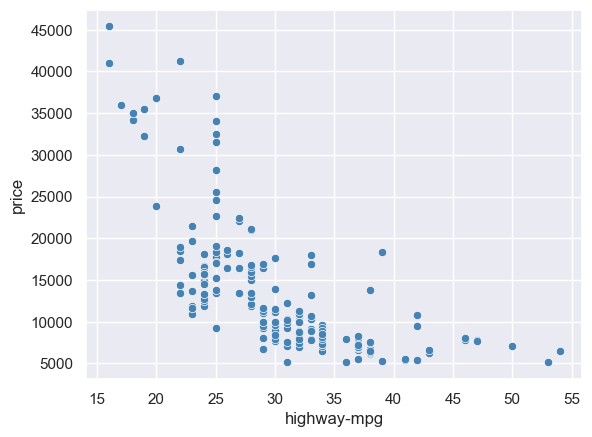

In [30]:
sns.scatterplot(data=df_clean,x="highway-mpg",y='price', color="steelblue")

**City MPG vs Price**

<Axes: xlabel='city-mpg', ylabel='price'>

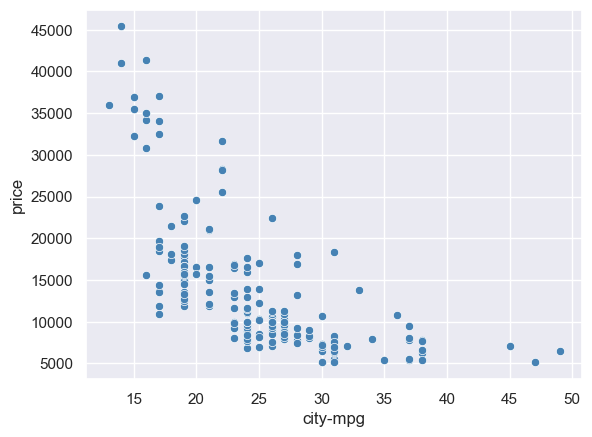

In [31]:
sns.scatterplot(data=df_clean,x="city-mpg",y='price', color="steelblue")

**Width vs Price**

<Axes: xlabel='width', ylabel='price'>

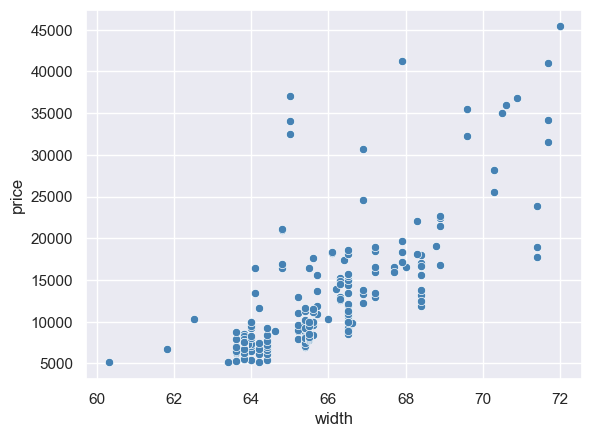

In [32]:
sns.scatterplot(data=df_clean,x="width",y='price', color="steelblue")

> **Insight:** Engine size, horsepower and curb weight are **positively** associated with price (bigger or more powerful cars cost more). City MPG and highway MPG are **negatively** associated with price (more fuel-efficient cars tend to be cheaper).

### 2.5 Average price by fuel type
A bar chart comparing the average price of petrol (gas) cars and diesel cars.

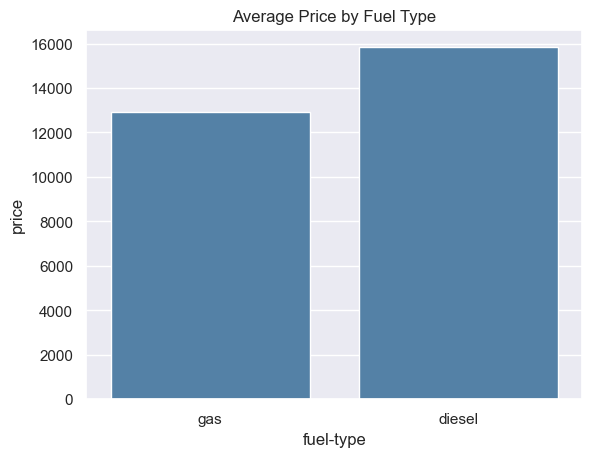

In [33]:
# Compare the average price for different vehicle categories.
sns.barplot(
    data=df_clean,
    x="fuel-type",
    y="price",
    errorbar=None,
    color="steelblue"
)
plt.title("Average Price by Fuel Type")
plt.show()

###  2.6 Correlation heatmap
The heatmap shows the correlation between every pair of numeric columns:
- Values close to **+1**: the two features increase together.
- Values close to **-1**: one increases while the other decreases.
- Values close to **0**: little linear relationship.

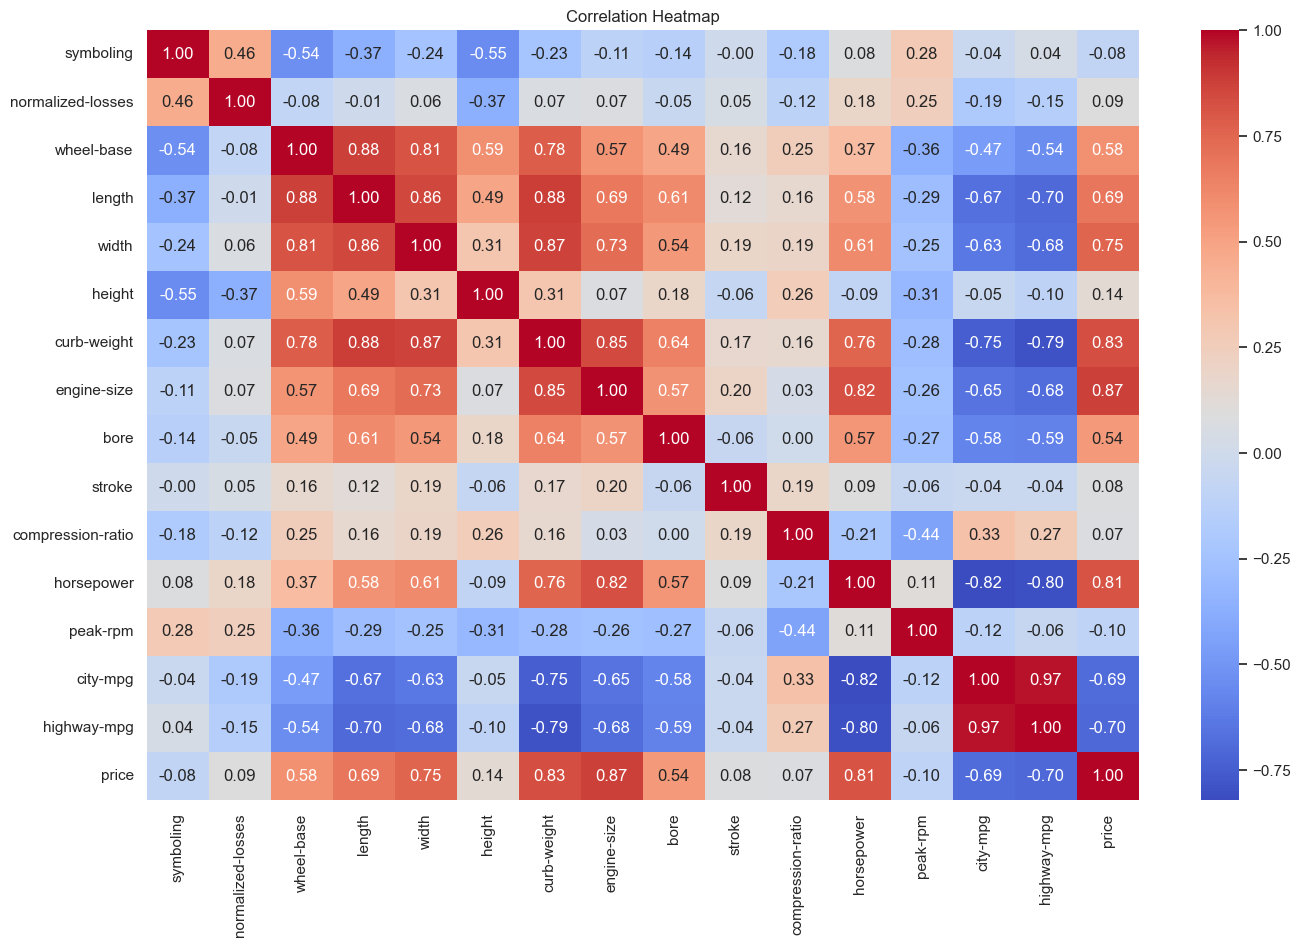

In [34]:
plt.figure(figsize=(16, 10))
sns.heatmap(
    df_clean.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

###  Key EDA findings

-  **Engine size, horsepower, curb weight and width** show positive relationships with price.
-  **City and highway fuel economy** tend to have negative relationships with price.
-  The **price distribution is right-skewed**: most cars are moderately priced and a small number are very expensive.
-  **Box plots flag potential outliers**, but they are not deleted automatically. High-priced luxury or performance cars may be genuine observations.
-  **City MPG and highway MPG are strongly related**, so they carry overlapping information.
-  Remember: correlation does not prove causation.

---
##  Split Data into Train and Test Sets

**What this step does:**
1. Removes rows whose `price` is missing (none in this dataset).
2. Separates the **features** `X` (all columns except price) from the **target** `y` (price).
3. Splits the data: **80% for training** and **20% for testing**.

**Expected result:** 160 training rows and 41 test rows.

In [35]:
# Drop only rows whose target (price) is missing
df_model = df.loc[df["price"].notna()].copy()
X = df_model.drop(columns=["price"])
y = df_model["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (160, 25)
X_test: (41, 25)
y_train: (160,)
y_test: (41,)


## 3. Data Preprocessing and Feature Transformation


---
## 3.1 Handle Missing Values After the Split

Missing values are filled **after** the train/test split so that the test set is treated as separate data. This is the correct order of operations for machine learning workflows.

### Define the feature groups

In [36]:
numeric_features = [
    "symboling", "normalized-losses", "wheel-base", "length", "width",
    "height", "curb-weight", "engine-size", "bore", "stroke",
    "compression-ratio", "horsepower", "peak-rpm", "city-mpg", "highway-mpg"
]
categorical_features = [
    "make", "fuel-type", "aspiration", "num-of-doors", "body-style",
    "drive-wheels", "engine-location", "engine-type", "num-of-cylinders", "fuel-system"
]

### Impute missing values with `fillna()`

Fit the fill values using **only `X_train`**. Apply those same values to both training and test data. Do not calculate separate medians or modes from `X_test`, because that lets information from the test set influence preprocessing.

| Column type | Fill method | Value learned from |
|---|---|---|
| Numerical | Median | `X_train` |
| Categorical | Mode (most frequent value) | `X_train` |


In [37]:
# Numerical columns: calculate medians from X_train only
for col in numeric_features:
    fill_value = X_train[col].median()
    X_train[col] = X_train[col].fillna(fill_value)
    X_test[col] = X_test[col].fillna(fill_value)


# Categorical columns: calculate modes from X_train only
for col in categorical_features:
    mode_values = X_train[col].mode(dropna=True)

    # Guard against a column that is entirely missing in the training data
    fill_value = mode_values.iloc[0] if not mode_values.empty else "Unknown"

    X_train[col] = X_train[col].fillna(fill_value)
    X_test[col] = X_test[col].fillna(fill_value)


# Verify that feature columns no longer contain missing values
print("Missing values in X_train:", X_train.isnull().sum().sum())
print("Missing values in X_test:", X_test.isnull().sum().sum())


Missing values in X_train: 0
Missing values in X_test: 0


---
##  3.2 Scaling and Encoding

Machine learning models need numbers on a similar scale and cannot read text categories directly, so we transform the features.

| Column type | Technique | What it does |
|---|---|---|
| Numerical | **StandardScaler** | Rescales each feature to mean 0 and standard deviation 1 |
| Categorical | **OneHotEncoder** | Turns each category into its own 0/1 column |

###  Choose the columns for each technique

In [38]:
# Select columns for scaling and one-hot encoding
standard_scaler = numeric_features
one_hot = categorical_features


### Build the ColumnTransformer
A `ColumnTransformer` applies the right transformation to the right columns in one step.

In [39]:
# Apply scaling to numeric columns and one-hot encoding to categorical columns
preprocessor = ColumnTransformer(
    transformers=[
        ('scaler', StandardScaler(), standard_scaler),
        ('onehot', OneHotEncoder(handle_unknown='ignore'), one_hot)
    ],
    remainder='drop'
)


In [40]:
preprocessor

,transformers,"[('scaler', ...), ('onehot', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,copy,True
,with_mean,True
,with_std,True


### Apply the ColumnTransformer

- `fit_transform()` on `X_train`: learns scaling parameters and category levels from training data, then transforms it.
- `transform()` on `X_test`: applies the already-learned transformations without refitting.
- `handle_unknown='ignore'` prevents errors if the test set contains a category not seen during training.


In [41]:
# Fit preprocessing on training data only; reuse it for test data
x_clean_train = preprocessor.fit_transform(X_train)
x_clean_test = preprocessor.transform(X_test)

print("Processed training shape:", x_clean_train.shape)
print("Processed test shape:", x_clean_test.shape)


Processed training shape: (160, 74)
Processed test shape: (41, 74)


---
## 4. Train Models and Compare Performance

Four regression models are trained on the training data and evaluated on the **test data**:

| Model | Short description |
|---|---|
| **Linear Regression** | Fits a straight-line relationship (simple baseline) |
| **Decision Tree** | Splits the data using a series of yes/no rules |
| **Random Forest** | Averages many decision trees (200 trees) |
| **Gradient Boosting** | Builds trees one after another, each correcting the previous one's errors |

### Evaluation metrics

| Metric | Meaning | Better when |
|---|---|---|
| **MAE** (Mean Absolute Error) | Average size of the prediction error | Lower |
| **RMSE** (Root Mean Squared Error) | Like MAE but penalises large errors more | Lower |
| **R²** | Share of the price variation explained by the model | Closer to 1 |

The results table is sorted by RMSE, so the best model appears at the top.

In [42]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Define models
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

results = []

for name, model in models.items():
    model.fit(x_clean_train, y_train)
    predictions = model.predict(x_clean_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": mean_squared_error(y_test, predictions) ** 0.5,
        "R2": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results).sort_values("RMSE")
results_df

,Model,MAE,RMSE,R2
3,Gradient Boosting,1554.132546,2472.194154,0.950046
1,Decision Tree,1988.048780,2946.728066,0.929028
2,Random Forest,1886.835827,2974.598470,0.927679
0,Linear Regression,1972.146507,3252.117101,0.913555


> **Observed result from the current notebook run:** Gradient Boosting has the lowest test RMSE (about 2,469), MAE about 1,553, and the highest R² (about 0.95) among the four models. These figures are based on one 80/20 split and should be rechecked after running the corrected notebook from top to bottom. Because the dataset is small, use cross-validation before making a strong claim that this model will generalize best.


---
##  Model Comparison Charts

Two charts make the results easy to compare:
1. **Error chart (MAE and RMSE):** shorter bars are better.
2. **R² chart:** taller bars are better.

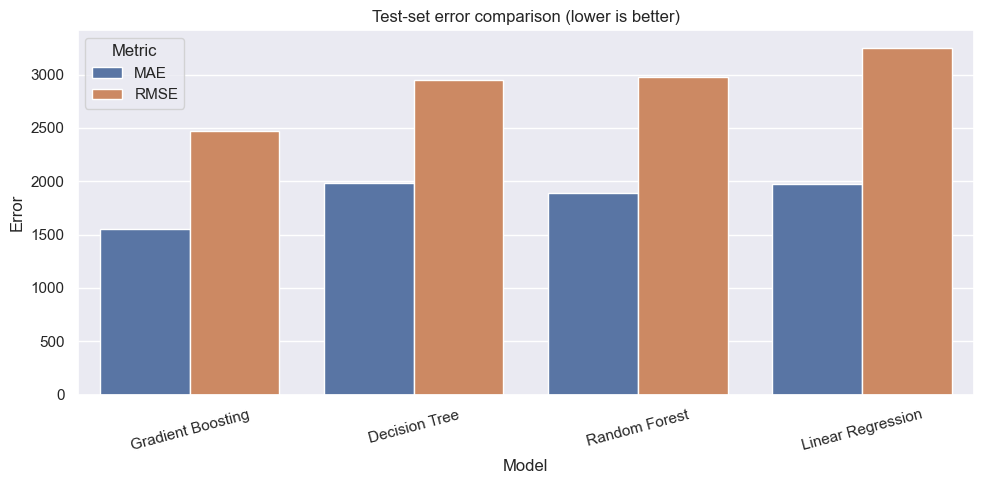

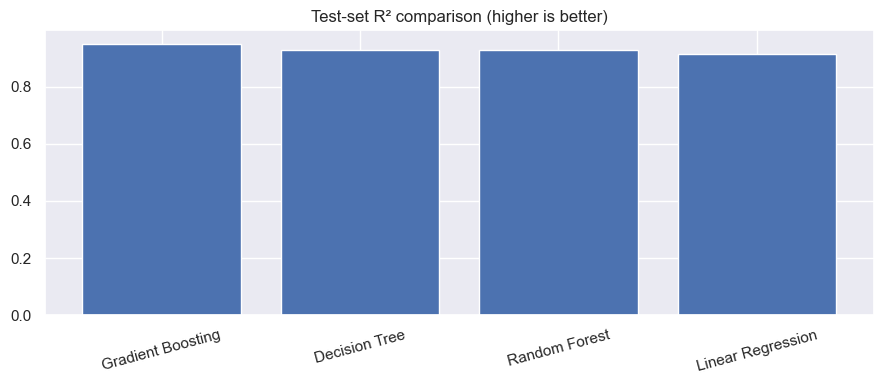

In [43]:
plot_df = results_df.melt(id_vars="Model", value_vars=["MAE", "RMSE"],
                         var_name="Metric", value_name="Error")
plt.figure(figsize=(10, 5))
sns.barplot(data=plot_df, x="Model", y="Error", hue="Metric")
plt.title("Test-set error comparison (lower is better)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4))
plt.bar(results_df["Model"], results_df["R2"])
plt.title("Test-set R² comparison (higher is better)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Actual vs. predicted prices and residual check

A useful final evaluation step is to inspect whether predictions follow the actual prices and whether residuals (actual minus predicted) show a systematic pattern. This complements MAE, RMSE, and R²; it does not replace a separate validation strategy.

Best model: Gradient Boosting
MAE: 1554.13
RMSE: 2472.19
R2: 0.95


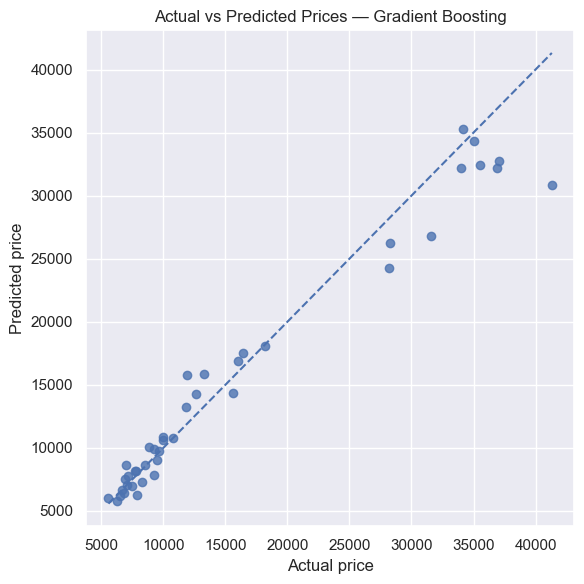

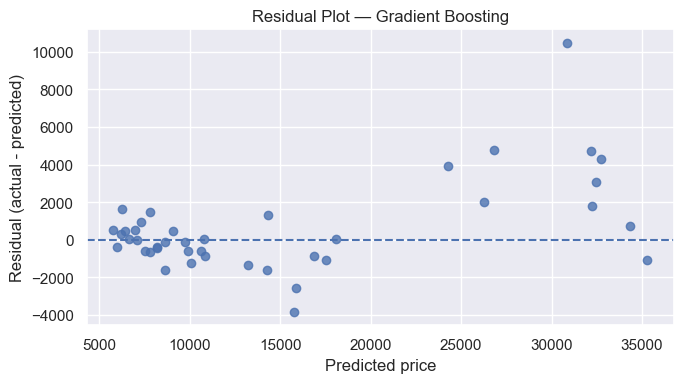

In [44]:
# Use the best model according to the current test-set RMSE table
best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]
best_predictions = best_model.predict(x_clean_test)
residuals = y_test.to_numpy() - best_predictions

print("Best model:", best_model_name)
print("MAE:", round(mean_absolute_error(y_test, best_predictions), 2))
print("RMSE:", round(mean_squared_error(y_test, best_predictions) ** 0.5, 2))
print("R2:", round(r2_score(y_test, best_predictions), 4))

# Actual vs predicted
plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_predictions, alpha=0.8)
min_value = min(float(y_test.min()), float(np.min(best_predictions)))
max_value = max(float(y_test.max()), float(np.max(best_predictions)))
plt.plot([min_value, max_value], [min_value, max_value], linestyle="--")
plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.title(f"Actual vs Predicted Prices — {best_model_name}")
plt.tight_layout()
plt.show()

# Residuals vs predicted values
plt.figure(figsize=(7, 4))
plt.scatter(best_predictions, residuals, alpha=0.8)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted price")
plt.ylabel("Residual (actual - predicted)")
plt.title(f"Residual Plot — {best_model_name}")
plt.tight_layout()
plt.show()


---
##  Conclusion, Challenges and Limitations

### Conclusion
- Car price can be predicted accurately from its specifications.
- **Gradient Boosting** performed best in the currently recorded held-out test results (R² about 0.95, RMSE about 2,469); rerun the notebook to refresh these values after preprocessing changes.
- Engine size, horsepower and curb weight are among the features most strongly linked to price.

### Challenges, techniques used and limitations

| Challenge | Technique used | Reason / limitation |
|---|---|---|
| Missing feature values marked with `?` | Read as `NaN`; median imputation for numeric and most-frequent (mode) imputation for categorical columns, applied after the train/test split | Filling after the split keeps the training and test sets separate. |
| Categorical features | One-hot encoding with `handle_unknown="ignore"` | Converts categories to model-readable columns and tolerates unseen test categories. |
| Features have different scales | StandardScaler for numeric features | Particularly helpful for Linear Regression; scaling is not usually essential for tree models but keeps preprocessing consistent. |
| Potential outliers and skewed prices | Inspected with EDA plots; not automatically removed | Some extreme values may be legitimate expensive cars. Investigate domain context before removing them. |
| Small dataset (201 rows) | Fixed held-out test split with reproducible `random_state=42` | Metrics can vary with the split; cross-validation would provide a more stable estimate. |
| Correlated predictors, e.g. city MPG and highway MPG | Correlation analysis | Correlated features can overlap in information; correlation does not establish causation. |

**Model selection:** the model with the lowest test RMSE is selected as the best candidate among the four tested models. Test-set performance is not a guarantee of performance on new markets; further validation, monitoring, and retraining may be required before production use.

**Reproducibility:** run this notebook from top to bottom after placing `auto_imports.csv` beside it. The notebook does not require `library.py`, a previously saved preprocessor, or a pre-imputed pickle file.
